# Step 7: find clear photos before and after a wildfire

**Goal:** pick the fire whose box has clear satellite photos both *before* and *after* it burned, and check that an official outline exists to grade against. Same idea as Step 1 for the floods.

New words:
- **Outline (perimeter):** the official line fire crews draw around a fire. It is our answer key later.
- **NIFC** and **MTBS:** two public sources of fire outlines. NIFC is shared by the fire agencies. MTBS is a national archive of larger fires.
- **Complex:** several fires managed as one. The Black Cove Complex has three pieces.
- **False color:** a picture that shows invisible infrared light as red and green, so burns stand out.

In [1]:
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import pandas as pd
import matplotlib.pyplot as plt
import hls, fires
step7 = importlib.import_module('07_find_fire_photos')  # reuse the script's functions
# The script saves pictures to files only. This line also shows them here in the notebook.
%matplotlib inline

## Sign in
Uses the login saved in `~/.netrc` (made once, by me, in the terminal). No password appears here.

In [2]:
hls.login();

## The three candidate fires and their official outlines
Each outline is downloaded from the agency's map service. As a check that we fetched the right shape, its size should match the official acres (about 7,670, 14,180 and 31,030).

In [3]:
rows = []
for name, fire in fires.FIRES.items():
    shape = fires.outline(name)
    km2 = fires.area_km2(shape)
    rows.append({'fire': name, 'outline from': fire['source'], 'started': fire['start'],
                 'km2': round(km2, 1), 'acres': round(km2 * fires.ACRES_PER_KM2), 'box': fires.box_around(shape)})
pd.DataFrame(rows)

,fire,outline from,started,km2,acres,box
0,Black Cove Complex (Mar 2025),NIFC,2025-03-19,31.1,7676,"(-82.391, 35.227, -82.188, 35.379)"
1,Tellico (Nov 2016),MTBS,2016-11-03,57.4,14172,"(-83.702, 35.235, -83.476, 35.364)"
2,Great Lakes (Apr 2023),MTBS,2023-04-19,125.6,31024,"(-77.197, 34.784, -76.952, 35.047)"


The box around each outline has a 3 km margin. The margin holds forest that did **not** burn, which we need later to compare against.

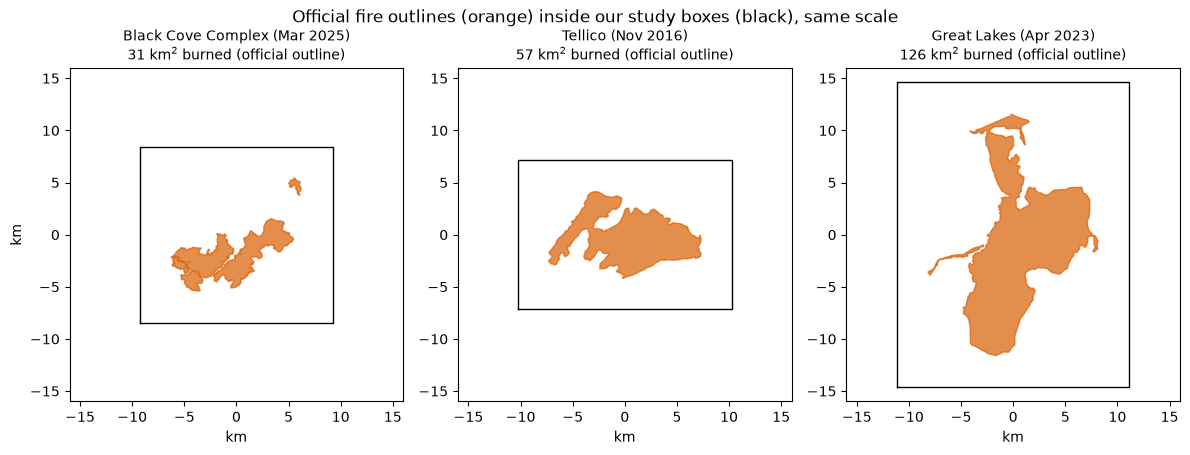

In [4]:
step7.plot_outlines('../figures/07_fire_outlines.png');

## Count clear photos for all three fire boxes
For every photo from 60 days before each fire to 90 days after, we read only the cloud stencil (Fmask) inside the box. This takes several minutes.

A photo counts as **good** if at least 80% of the whole box is clear. Days are counted from the day the fire started, so fires from different years line up.

In [5]:
tables = []
for name, fire in fires.FIRES.items():
    bbox = fires.box_around(fires.outline(name))
    tables.append(step7.measure_fire(name, bbox, fire['start'], verbose=False))
df = pd.concat(tables, ignore_index=True)
step7.summarize(df)

,fire,photos,good before,last good before (days),good after,first good after (days),tiles
0,Black Cove Complex (Mar 2025),50,13,-1,6,2,T17SLU T17SLV
1,Tellico (Nov 2016),33,2,-20,3,23,T16SGE T17SKV
2,Great Lakes (Apr 2023),58,10,-1,6,1,T18STD T18SUD


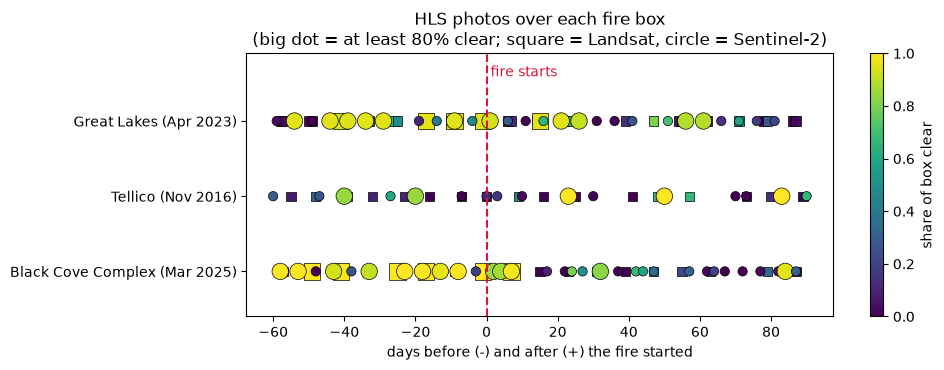

In [6]:
step7.plot_timeline(df, '../figures/07_fire_photos_timeline.png');

## Two things that looked odd, checked
**1. Tellico has no good Landsat photo.** Is that a bug? `seen` is the share of the box the satellite saw at all.

In [7]:
t = df[df['fire'].str.startswith('Tellico') & (df['satellite'] == 'Landsat')]
t.assign(date=t['date'].dt.date)[['date', 'day', 'tile_cloud_pct', 'seen', 'clear']].round(2)

,date,day,tile_cloud_pct,seen,clear
51,2016-09-09,-55,65.0,0.66,0.07
52,2016-09-16,-48,36.0,1.00,0.31
55,2016-09-25,-39,9.0,0.62,0.58
56,2016-10-02,-32,63.0,0.99,0.10
58,2016-10-11,-23,54.0,0.68,0.10
60,2016-10-18,-16,81.0,0.99,0.01
62,2016-10-27,-7,100.0,0.72,0.00
63,2016-11-03,0,70.0,0.96,0.03
66,2016-11-12,9,3.0,0.70,0.49
68,2016-11-19,16,86.0,0.97,0.00


Not a bug. On about half the passes Landsat sees only 60-70% of the box: the edge of its flight path cuts through it. A photo that sees 70% of a box can never be 80% clear.

**2. Black Cove's first "good after" photos are during the fire.** It started March 19 and kept growing until about March 31. Here are its photos in the two months after it started:

In [8]:
b = df[df['fire'].str.startswith('Black Cove') & df['day'].between(1, 60) & (df['clear'] >= 0.5)]
b.assign(date=b['date'].dt.date)[['date', 'satellite', 'day', 'clear']].round(2)

,date,satellite,day,clear
19,2025-03-21,Sentinel-2,2,0.85
20,2025-03-23,Sentinel-2,4,0.87
21,2025-03-26,Landsat,7,1.00
22,2025-03-26,Sentinel-2,7,0.98
27,2025-04-12,Sentinel-2,24,0.80
30,2025-04-20,Sentinel-2,32,0.83
33,2025-04-30,Sentinel-2,42,0.68
34,2025-05-02,Sentinel-2,44,0.59


After the fire stopped growing, the usable photos are **April 12** (80% clear, a hair under the bar) and **April 20** (83%).

## First look: can we see the scar?
Black Cove box, one day before the fire (March 18) and one week in (March 26). Both are Landsat and 100% clear. Shortwave infrared is shown as red, so burned ground looks red-brown. The white line is the official outline.

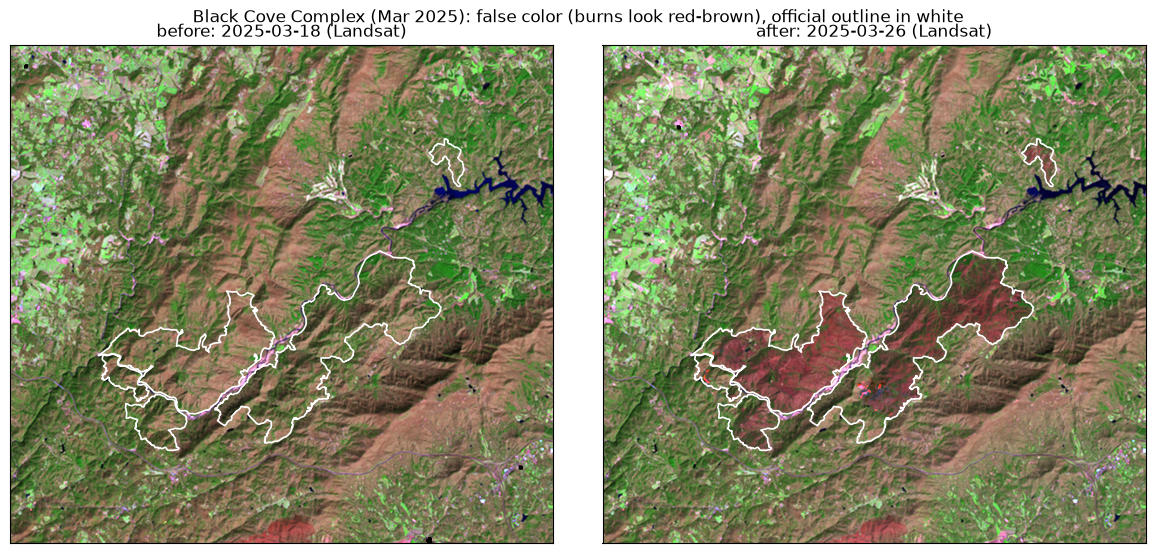

In [9]:
step7.plot_first_look('Black Cove Complex (Mar 2025)', '2025-03-18', '2025-03-26', 'Landsat',
                      '../figures/07_black_cove_first_look.png');

## What we learned
- **All three fires have an official outline**, and each downloaded outline matches the official size.
- **Black Cove Complex is the study fire.** It has 13 good photos before (the closest is one day before, 100% clear) and usable photos after the fire stopped (April 12 and April 20).
- **Great Lakes is a strong backup** (10 good before, 6 good after). **Tellico is the weakest:** 2 good before, the first good after is day 23, and Landsat's path edge cuts its box.
- **The scar is clearly visible** and fills the official outline, so this is not a hopeless case.
- **March 26 is too early for a final map.** The lower-left lobe of the outline had not burned yet, and orange dots show active flames.
- **There is an older burn in the box.** The red patch at the bottom edge is in *both* photos. A before-minus-after rule should ignore it, because it did not change. That is a useful test for the next step.
- **A limit to remember:** the Black Cove outlines are marked "auto-generated" by NIFC, not "certified".